#### Imports and project configuration

###### Import the libraries used for video reading, detection, tracking, reporting and visualization. Set up the project paths and the main experiment parameters in one place.

In [1]:
from pathlib import Path
import time
import csv

import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from IPython.display import display, Video

# The notebook should be opened from the AeroTrack project folder.
PROJECT_DIR = Path.cwd()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Change this to the exact name of your drone video.
VIDEO_FILENAME = "drone_video.mov"
VIDEO_PATH = DATA_DIR / VIDEO_FILENAME

# Main experiment settings.
MODEL_NAME = "yolo26n.pt"       # Lightweight pretrained baseline detector
TRACKER_CONFIG = "botsort.yaml" # BoT-SORT multi-object tracker
PERSON_CLASS_ID = 0             # COCO class 0 is person
CONFIDENCE_THRESHOLD = 0.25
IMAGE_SIZE = 640
PREVIEW_SECONDS = 5

OUTPUT_VIDEO_PATH = OUTPUT_DIR / "drone_tracked_botsort.mp4"
TRACK_SUMMARY_PATH = OUTPUT_DIR / "observed_tracker_ids.csv"
FRAME_SUMMARY_PATH = OUTPUT_DIR / "per_frame_metrics.csv"

print("Project folder:", PROJECT_DIR)
print("Video path:", VIDEO_PATH)
print("Output folder:", OUTPUT_DIR)

Project folder: c:\Users\anyan\source\repos\AeroTrack
Video path: c:\Users\anyan\source\repos\AeroTrack\data\drone_video.mov
Output folder: c:\Users\anyan\source\repos\AeroTrack\outputs


#### Check the environment and GPU

###### Use the NVIDIA GPU when PyTorch can access CUDA. If CUDA is unavailable, the notebook falls back to CPU, although processing will be considerably slower.

In [2]:
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version used by PyTorch:", torch.version.cuda)
    gpu_memory_gb = (
        torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    )
    print("GPU memory (GB):", round(gpu_memory_gb, 2))
else:
    DEVICE = "cpu"
    print("CUDA is not available. Using CPU.")

print("Selected device:", DEVICE)

PyTorch version: 2.15.0+cu132
OpenCV version: 5.1.0
GPU available: NVIDIA GeForce RTX 3050 Ti Laptop GPU
CUDA version used by PyTorch: 13.2
GPU memory (GB): 4.0
Selected device: 0


#### Load and inspect the drone video

###### Check that the input file exists and can be opened. Read its resolution, frame rate, reported frame count and estimated duration.

###### The reported frame count is metadata supplied by the video decoder. The actual number of frames successfully read will be recorded during processing.

In [3]:
if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH}\n"
        "Copy your video into the data folder or update VIDEO_FILENAME."
    )

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(
        "OpenCV could not open the video. Check the file and its codec."
    )

VIDEO_WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
VIDEO_HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
VIDEO_FPS = cap.get(cv2.CAP_PROP_FPS)
REPORTED_FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if VIDEO_FPS <= 0:
    VIDEO_FPS = 25.0

ESTIMATED_DURATION = (
    REPORTED_FRAME_COUNT / VIDEO_FPS
    if REPORTED_FRAME_COUNT > 0 else None
)

print(f"Resolution: {VIDEO_WIDTH} x {VIDEO_HEIGHT}")
print(f"FPS: {VIDEO_FPS:.2f}")
print("Frames reported by decoder:", REPORTED_FRAME_COUNT)

if ESTIMATED_DURATION is not None:
    print(f"Estimated duration: {ESTIMATED_DURATION:.1f} seconds")

cap.release()

Resolution: 3840 x 2160
FPS: 29.97
Frames reported by decoder: 2272
Estimated duration: 75.8 seconds


##### Preview the input video

###### Display one frame from the original video. This is a quick visual check that the file is being read correctly before running the detector.

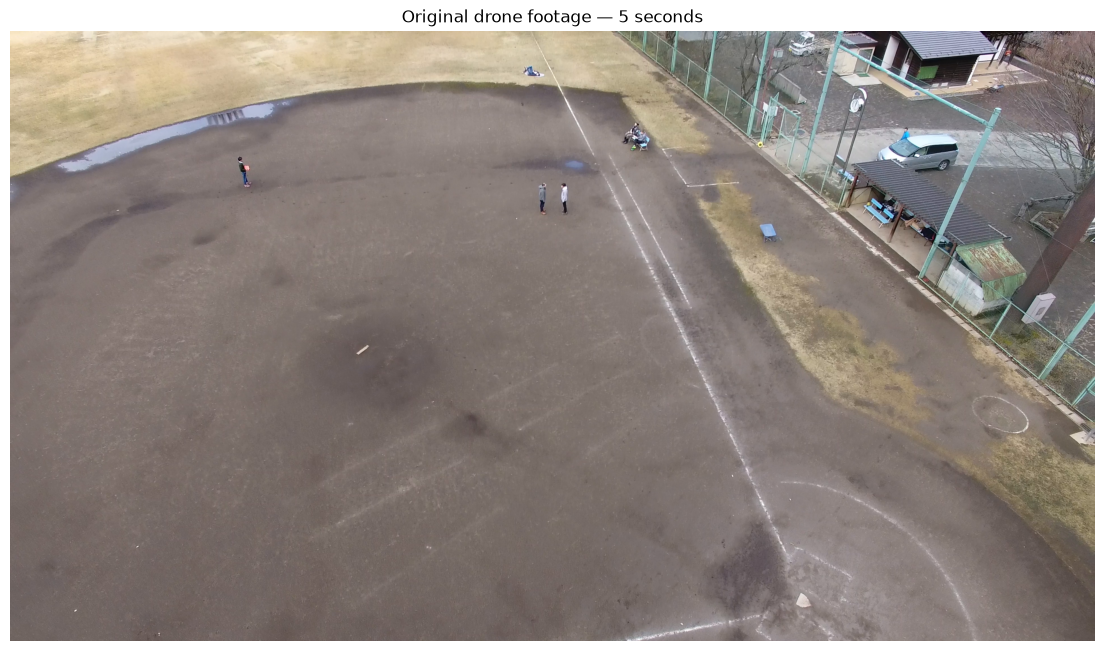

In [4]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_MSEC, PREVIEW_SECONDS * 1000)

success, preview_frame = cap.read()
cap.release()

if not success:
    raise RuntimeError(
        f"Could not read a frame at {PREVIEW_SECONDS} seconds."
    )

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Original drone footage — {PREVIEW_SECONDS} seconds")
plt.axis("off")
plt.show()

#### Load the YOLO person detector

###### Load the pretrained YOLO26n model. For this baseline, we use the COCO `person` class (class ID 0).

###### The model weights are downloaded automatically the first time if they are not already available.

In [5]:
model = YOLO(MODEL_NAME)

print("Loaded model:", MODEL_NAME)
print("Person class ID:", PERSON_CLASS_ID)
print("Person class name:", model.names[PERSON_CLASS_ID])

Loaded model: yolo26n.pt
Person class ID: 0
Person class name: person


#### Test person detection on one frame

###### Run detection only (without tracking) on the preview frame. This verifies that the model detects people and draws bounding boxes before we process the full video.

###### The confidence value shown beside each box is the detector's confidence for that frame. It is not a tracking ID.

People detected in preview frame: 4


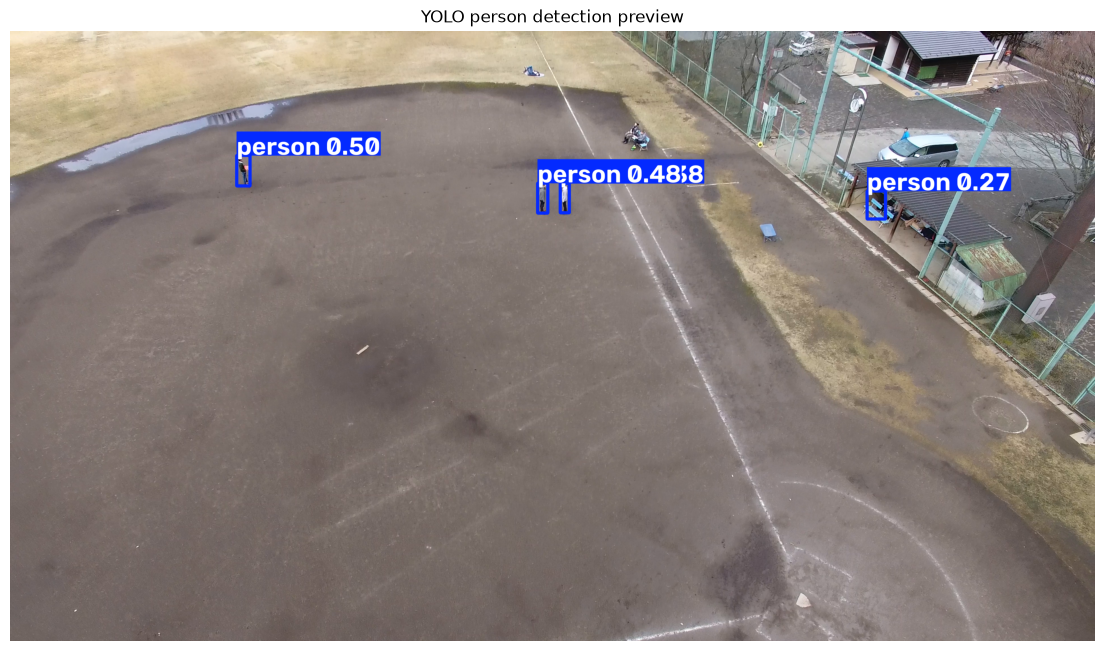

In [6]:
preview_result = model.predict(
    source=preview_frame,
    classes=[PERSON_CLASS_ID],
    conf=CONFIDENCE_THRESHOLD,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    verbose=False
)[0]

preview_detection_count = (
    len(preview_result.boxes)
    if preview_result.boxes is not None else 0
)

print("People detected in preview frame:", preview_detection_count)

preview_annotated = preview_result.plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview_annotated, cv2.COLOR_BGR2RGB))
plt.title("YOLO person detection preview")
plt.axis("off")
plt.show()

##### Track people across the complete video

This is the main processing section.

For each frame:
1. Read the next video frame.
2. Run YOLO person detection and BoT-SORT tracking.
3. Collect any tracker IDs returned by the model.
4. Draw boxes and IDs on the frame.
5. Write the annotated frame to the output video.
6. Record frame-level detection and tracking statistics.

`persist=True` tells Ultralytics to keep tracker state between consecutive frames. Do not shuffle the frames or process them out of order.

The default BoT-SORT configuration includes camera-motion compensation settings. We are using the standard `botsort.yaml` configuration here so that this remains a reproducible baseline.

In [7]:
# Open the source video.
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not reopen the input video.")

# Use source dimensions and FPS for the output video.
source_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
source_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
source_fps = cap.get(cv2.CAP_PROP_FPS)

if source_fps <= 0:
    source_fps = 25.0

# Create the annotated video writer.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO_PATH),
    fourcc,
    source_fps,
    (source_width, source_height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError(
        "Could not create the output video. Check the output folder and codec."
    )

# Overall experiment statistics.
unique_tracker_ids = set()
track_observations = {}
frame_records = []

frames_processed = 0
frames_with_people = 0
total_person_detections = 0

processing_start = time.time()

while True:
    success, frame = cap.read()

    if not success:
        break

    frames_processed += 1

    # Detect people and track them from the previous frame.
    result = model.track(
        source=frame,
        persist=True,
        tracker=TRACKER_CONFIG,
        classes=[PERSON_CLASS_ID],
        conf=CONFIDENCE_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        verbose=False
    )[0]

    # Number of person detections in this frame.
    detection_count = (
        len(result.boxes)
        if result.boxes is not None else 0
    )

    total_person_detections += detection_count

    if detection_count > 0:
        frames_with_people += 1

    # Collect tracker IDs when the tracker has assigned them.
    frame_ids = []

    if result.boxes is not None and result.boxes.id is not None:
        frame_ids = result.boxes.id.int().cpu().tolist()

        for tracker_id in frame_ids:
            tracker_id = int(tracker_id)
            unique_tracker_ids.add(tracker_id)

            if tracker_id not in track_observations:
                track_observations[tracker_id] = {
                    "tracker_id": tracker_id,
                    "first_frame": frames_processed,
                    "last_frame": frames_processed,
                    "frames_observed": 0
                }

            track_observations[tracker_id]["last_frame"] = frames_processed
            track_observations[tracker_id]["frames_observed"] += 1

    # Save frame-level statistics.
    frame_records.append({
        "frame": frames_processed,
        "detections": detection_count,
        "tracker_ids_observed": len(frame_ids)
    })

    # Draw the boxes, class labels and tracker IDs.
    annotated_frame = result.plot()

    # Write the annotated frame to the output video.
    writer.write(annotated_frame)

    # Print progress every 100 frames.
    if frames_processed % 100 == 0:
        elapsed = time.time() - processing_start
        print(
            f"Processed {frames_processed} frames | "
            f"Detections: {total_person_detections} | "
            f"Unique tracker IDs: {len(unique_tracker_ids)} | "
            f"Elapsed: {elapsed:.1f}s"
        )

# Release video resources.
cap.release()
writer.release()

processing_time = time.time() - processing_start

print("\nProcessing complete.")
print("Frames successfully processed:", frames_processed)
print("Frames containing detections:", frames_with_people)
print("Total person detections across frames:", total_person_detections)
print("Unique tracker IDs observed:", len(unique_tracker_ids))
print("Processing time (seconds):", round(processing_time, 2))
print("Annotated video:", OUTPUT_VIDEO_PATH)

Processed 100 frames | Detections: 330 | Unique tracker IDs: 5 | Elapsed: 17.4s
Processed 200 frames | Detections: 642 | Unique tracker IDs: 7 | Elapsed: 35.0s
Processed 300 frames | Detections: 964 | Unique tracker IDs: 11 | Elapsed: 53.2s
Processed 400 frames | Detections: 1397 | Unique tracker IDs: 17 | Elapsed: 70.1s
Processed 500 frames | Detections: 1854 | Unique tracker IDs: 20 | Elapsed: 86.5s
Processed 600 frames | Detections: 2114 | Unique tracker IDs: 31 | Elapsed: 103.0s
Processed 700 frames | Detections: 2672 | Unique tracker IDs: 41 | Elapsed: 120.5s
Processed 800 frames | Detections: 3021 | Unique tracker IDs: 44 | Elapsed: 137.1s
Processed 900 frames | Detections: 3193 | Unique tracker IDs: 48 | Elapsed: 171.8s
Processed 1000 frames | Detections: 3330 | Unique tracker IDs: 52 | Elapsed: 220.9s
Processed 1100 frames | Detections: 3448 | Unique tracker IDs: 56 | Elapsed: 271.5s
Processed 1200 frames | Detections: 3523 | Unique tracker IDs: 57 | Elapsed: 322.0s
Processed 1

#### Export tracker and frame summaries

###### Create two CSV files:

###### - `observed_tracker_ids.csv`: one row for each tracker ID observed, with its first frame, last frame and number of frames in which it was observed.
###### - `per_frame_metrics.csv`: detection and tracker-ID observations for each processed frame.

###### These are useful for later analysis. A tracker ID is temporary and does not prove that the system has identified a unique real-world individual.

In [8]:
# Save one row per tracker ID.
track_columns = [
    "tracker_id",
    "first_frame",
    "last_frame",
    "frames_observed"
]

track_df = pd.DataFrame(
    list(track_observations.values()),
    columns=track_columns
)

if not track_df.empty:
    track_df = track_df.sort_values("tracker_id")

track_df.to_csv(TRACK_SUMMARY_PATH, index=False)

# Save per-frame statistics.
frame_df = pd.DataFrame(frame_records)
frame_df.to_csv(FRAME_SUMMARY_PATH, index=False)

print("Tracker summary saved:", TRACK_SUMMARY_PATH)
print("Frame metrics saved:", FRAME_SUMMARY_PATH)

display(track_df.head(20))

Tracker summary saved: c:\Users\anyan\source\repos\AeroTrack\outputs\observed_tracker_ids.csv
Frame metrics saved: c:\Users\anyan\source\repos\AeroTrack\outputs\per_frame_metrics.csv


,tracker_id,first_frame,last_frame,frames_observed
0,1,1,425,380
1,2,1,521,513
2,3,1,544,488
3,4,5,25,6
4,9,21,59,24
5,29,131,146,12
6,54,197,197,1
7,61,218,219,2
8,85,243,284,13
9,87,244,248,5


#### Review the results

###### Calculate the average processing FPS and display the key statistics.

###### Processing FPS is the number of video frames processed divided by elapsed processing time. It is not necessarily the same as the source video's playback FPS.

In [9]:
processing_fps = (
    frames_processed / processing_time
    if processing_time > 0 else 0
)

summary = pd.DataFrame([
    {"metric": "Source resolution", "value": f"{VIDEO_WIDTH} x {VIDEO_HEIGHT}"},
    {"metric": "Source FPS", "value": round(source_fps, 2)},
    {"metric": "Frames reported by decoder", "value": REPORTED_FRAME_COUNT},
    {"metric": "Frames successfully processed", "value": frames_processed},
    {"metric": "Frames containing people", "value": frames_with_people},
    {"metric": "Total person detections", "value": total_person_detections},
    {"metric": "Unique tracker IDs observed", "value": len(unique_tracker_ids)},
    {"metric": "Processing time (seconds)", "value": round(processing_time, 2)},
    {"metric": "Processing speed (FPS)", "value": round(processing_fps, 2)}
])

display(summary)

,metric,value
0,Source resolution,3840 x 2160
1,Source FPS,29.97
2,Frames reported by decoder,2272
3,Frames successfully processed,2250
4,Frames containing people,1560
5,Total person detections,5146
6,Unique tracker IDs observed,76
7,Processing time (seconds),639.96
8,Processing speed (FPS),3.52


#### Display the annotated video

###### Open the saved output video to review whether the boxes follow people and whether tracker IDs remain stable.

In [10]:
if OUTPUT_VIDEO_PATH.exists():
    display(Video(
        str(OUTPUT_VIDEO_PATH),
        embed=False,
        width=900
    ))
else:
    print("Annotated video was not created:", OUTPUT_VIDEO_PATH)

#### Section 11 — Interpretation and known limitations

### What this baseline achieves

- Detects objects classified as people by the pretrained COCO model.
- Associates detections across consecutive frames using BoT-SORT.
- Draws bounding boxes and temporary tracker IDs.
- Saves an annotated video.
- Reports observed tracker IDs and detection statistics.

### What it does not achieve yet

1. **Reliable aerial detection:** The pretrained model is not specifically fine-tuned for drone imagery. Small or distant people may be missed.
2. **Perfect track continuity:** A person may receive a new ID after occlusion, missed detection or difficult camera movement.
3. **Global person re-identification:** The system does not yet recognize a person who disappears and returns later under a new tracker ID.
4. **Verified unique-person counting:** The number of tracker IDs is only a baseline count, not the final number of unique individuals.

### Part 1 conclusion

Part 1 establishes the baseline pipeline for person detection, multi-object tracking and basic tracker-ID counting. The next development stage will improve detection by fine-tuning a YOLO model on aerial imagery.